**Import Library**

In [81]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings('ignore')
print('Đã khai báo xong toàn bộ thư viện!')

Đã khai báo xong toàn bộ thư viện!


**Read Data & Feature Engineering**

In [82]:
# Đọc file dữ liệu[cite: 6]
df = pd.read_csv('f1_data.csv')

# Đảm bảo cột position là số và tự động tạo cột nhãn is_podium (Top 3)[cite: 6]
df['position'] = pd.to_numeric(df['position'], errors='coerce')
if 'is_podium' not in df.columns:
    df['is_podium'] = (df['position'] <= 3).astype(int)
df = df.dropna(subset=['is_podium'])

# Sắp xếp theo trình tự thời gian để tính toán phong độ chính xác[cite: 6]
df = df.sort_values(by=['driver', 'season', 'round']).reset_index(drop=True)

# Khai thác đặc trưng 1: Vị trí xuất phát trung bình 3 chặng gần nhất (Phong độ gần đây)[cite: 6]
df['recent_avg_grid'] = (
    df.groupby('driver')['grid'].shift(1).rolling(3, min_periods=1).mean().round(2)
)

# Khai thác đặc trưng 2: Tỷ lệ lên podium của tay đua tại trường đua trong quá khứ[cite: 6]
circuit_podium_stats = (
    df.groupby(['driver', 'circuit'])['is_podium']
    .expanding()
    .mean()
    .reset_index(level=[0, 1], drop=True)
)
df['circuit_driver_podium_rate'] = circuit_podium_stats.shift(1).fillna(0)

display(df.head(6))

,season,round,date,circuit,driver,constructor,grid,position,points,status,laps,is_podium,recent_avg_grid,circuit_driver_podium_rate
0,2019,1,2019-03-17,Albert Park Grand Prix Circuit,albon,toro_rosso,13,14,0,+1 Lap,57,0,NaN,0.0
1,2019,2,2019-03-31,Bahrain International Circuit,albon,toro_rosso,12,9,2,Finished,57,0,13.00,0.0
2,2019,3,2019-04-14,Shanghai International Circuit,albon,toro_rosso,0,10,1,+1 Lap,55,0,12.50,0.0
3,2019,4,2019-04-28,Baku City Circuit,albon,toro_rosso,11,11,0,+1 Lap,50,0,8.33,0.0
4,2019,5,2019-05-12,Circuit de Barcelona-Catalunya,albon,toro_rosso,11,11,0,Finished,66,0,7.67,0.0
5,2020,1,2020-07-05,Red Bull Ring,albon,red_bull,4,13,0,Electronics,67,0,7.33,0.0


**Info Data**

In [83]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1700 entries, 0 to 1699
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   season                      1700 non-null   int64  
 1   round                       1700 non-null   int64  
 2   date                        1700 non-null   object 
 3   circuit                     1700 non-null   object 
 4   driver                      1700 non-null   object 
 5   constructor                 1700 non-null   object 
 6   grid                        1700 non-null   int64  
 7   position                    1700 non-null   int64  
 8   points                      1700 non-null   int64  
 9   status                      1700 non-null   object 
 10  laps                        1700 non-null   int64  
 11  is_podium                   1700 non-null   int64  
 12  recent_avg_grid             1699 non-null   float64
 13  circuit_driver_podium_rate  1700 

***visualization***

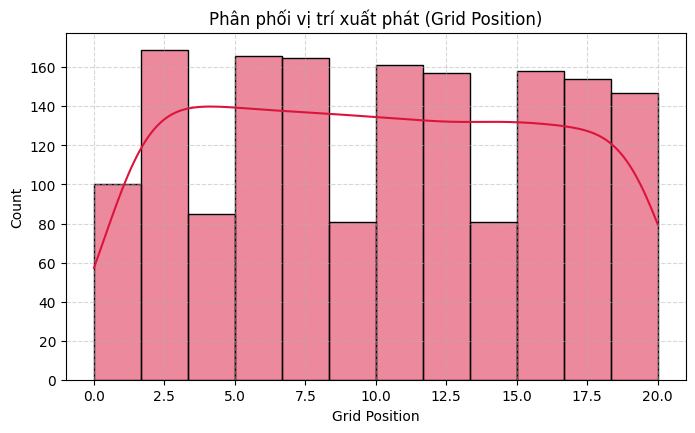

In [84]:
plt.figure(figsize=(8, 4.5))
df_filtered = df[df['grid'] <= 20]
sns.histplot(df_filtered['grid'], kde=True, color='crimson')
plt.title('Phân phối vị trí xuất phát (Grid Position)')
plt.xlabel('Grid Position')
plt.ylabel('Count')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Describe**

In [85]:
df.describe()

,season,round,grid,position,points,laps,is_podium,recent_avg_grid,circuit_driver_podium_rate
count,1700.000000,1700.000000,1700.000000,1700.000000,1700.000000,1700.000000,1700.000000,1699.000000,1700.000000
mean,2018.000000,2.899412,10.698235,10.801765,5.073529,50.872353,0.151765,10.681042,0.149060
std,4.900421,1.372778,6.183395,6.142998,7.250573,16.760426,0.358898,5.382295,0.278985
min,2010.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
25%,2014.000000,2.000000,5.000000,5.000000,0.000000,51.000000,0.000000,6.330000,0.000000
50%,2018.000000,3.000000,11.000000,11.000000,0.000000,56.000000,0.000000,10.670000,0.000000
75%,2022.000000,4.000000,16.000000,16.000000,10.000000,57.000000,0.000000,14.670000,0.200000
max,2026.000000,6.000000,24.000000,24.000000,26.000000,78.000000,1.000000,24.000000,1.000000


**Chia tập train/val/test**

In [86]:
num_features = [
    'season',
    'round',
    'grid',
    'laps',
    'recent_avg_grid',
    'circuit_driver_podium_rate',
]
cat_features = ['circuit', 'constructor', 'driver']

X = df.drop(columns=['is_podium', 'position', 'date', 'status', 'points'])
y = df['is_podium']

# Bước 1: Tách tập Test ra riêng (20% tổng dữ liệu)[cite: 6]
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Bước 2: Chia phần còn lại thành Train (60% tổng) và Validation (20% tổng)[cite: 6]
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, random_state=42, stratify=y_train_val
)

print(f'Kích thước tập Train: {X_train.shape[0]:,} dòng')
print(f'Kích thước tập Validation: {X_val.shape[0]:,} dòng')
print(f'Kích thước tập Test: {X_test.shape[0]:,} dòng')

Kích thước tập Train: 1,020 dòng
Kích thước tập Validation: 340 dòng
Kích thước tập Test: 340 dòng


**Tiền xử lý**


In [87]:

num_transformer = Pipeline(steps=[('scaler', StandardScaler())])

cat_transformer = Pipeline(
    steps=[
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features),
    ],
    remainder='drop',
)

# Fit_transform trên tập Train và transform trên Val/Test để tránh Data Leakage[cite: 6]
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print(f'Kích thước X_train sau xử lý: {X_train_processed.shape}')
print(f'Kích thước X_test sau xử lý: {X_test_processed.shape}')

Kích thước X_train sau xử lý: (1020, 127)
Kích thước X_test sau xử lý: (340, 127)


**Huấn luyện mô hình**

In [88]:
model = LogisticRegression(
    class_weight='balanced', max_iter=1000, random_state=42
)

print('Bắt đầu huấn luyện mô hình Logistic Regression...')
model.fit(X_train_processed, y_train)
print('Huấn luyện mô hình thành công!')

Bắt đầu huấn luyện mô hình Logistic Regression...
Huấn luyện mô hình thành công!


**Đánh giá và so sánh**

ĐỘ CHÍNH XÁC TỔNG QUAN (Accuracy): 89.12%
ĐỘ ĐO ROC-AUC: 0.9490

--- BÁO CÁO PHÂN LOẠI CHI TIẾT ---
              precision    recall  f1-score   support

   Không cúp       0.98      0.89      0.93       288
      Có cúp       0.60      0.88      0.71        52

    accuracy                           0.89       340
   macro avg       0.79      0.89      0.82       340
weighted avg       0.92      0.89      0.90       340



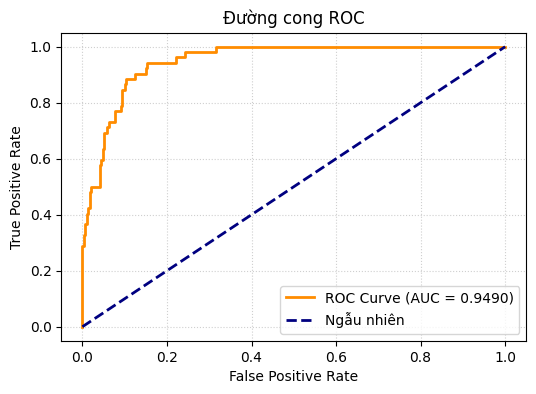

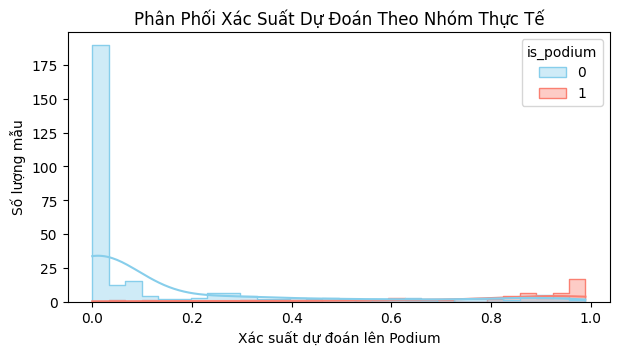

In [89]:
y_pred = model.predict(X_test_processed)
y_prob = model.predict_proba(X_test_processed)[:, 1]

accuracy = accuracy_score(y_test, y_pred) * 100
print(f'ĐỘ CHÍNH XÁC TỔNG QUAN (Accuracy): {accuracy:.2f}%')
try:
    print(f'ĐỘ ĐO ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}\n')
except:
    pass

print('--- BÁO CÁO PHÂN LOẠI CHI TIẾT ---')
print(classification_report(y_test, y_pred, target_names=['Không cúp', 'Có cúp']))

# 1. Vẽ Đường cong ROC
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(6, 4))
plt.plot(
    fpr,
    tpr,
    color='darkorange',
    lw=2,
    label=f'ROC Curve (AUC = {auc_score:.4f})',
)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Ngẫu nhiên')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Đường cong ROC')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# 2. Vẽ Phân phối xác suất dự đoán
plt.figure(figsize=(7, 3.5))
sns.histplot(
    x=y_prob,
    hue=y_test,
    bins=30,
    kde=True,
    palette={0: 'skyblue', 1: 'salmon'},
    element='step',
    alpha=0.4,
)
plt.title('Phân Phối Xác Suất Dự Đoán Theo Nhóm Thực Tế')
plt.xlabel('Xác suất dự đoán lên Podium')
plt.ylabel('Số lượng mẫu')
plt.show()

**Phân tích lỗi (Confusion Matrix)**

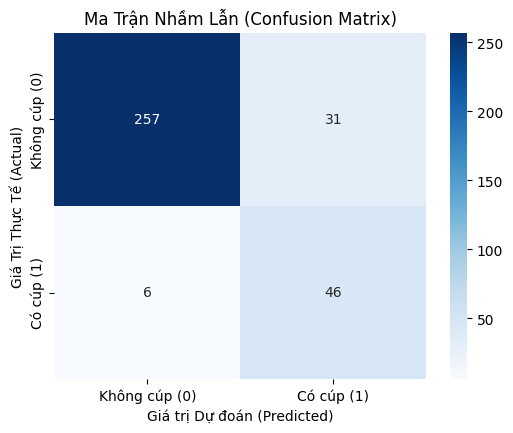

Số mẫu dự đoán đúng Không cúp (True Negative): 257
Số mẫu dự đoán nhầm thành Có cúp (False Positive - Lỗi loại 1): 31
Số mẫu bỏ sót, thực tế có cúp nhưng đoán không (False Negative - Lỗi loại 2): 6
Số mẫu dự đoán đúng Có cúp (True Positive): 46


In [90]:
# Tính toán ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4.5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Không cúp (0)', 'Có cúp (1)'],
    yticklabels=['Không cúp (0)', 'Có cúp (1)'],
)
plt.title('Ma Trận Nhầm Lẫn (Confusion Matrix)')
plt.xlabel('Giá trị Dự đoán (Predicted)')
plt.ylabel('Giá Trị Thực Tế (Actual)')
plt.show()

# In giải thích chi tiết lỗi
TN, FP, FN, TP = cm.ravel()
print(f'Số mẫu dự đoán đúng Không cúp (True Negative): {TN}')
print(f'Số mẫu dự đoán nhầm thành Có cúp (False Positive - Lỗi loại 1): {FP}')
print(
    f'Số mẫu bỏ sót, thực tế có cúp nhưng đoán không (False Negative - Lỗi loại'
    f' 2): {FN}'
)
print(f'Số mẫu dự đoán đúng Có cúp (True Positive): {TP}')

**PHÂN TÍCH LỖI & BIỂU ĐỒ TRỌNG SỐ ĐẶC TRƯNG**

- Tổng số ca dự đoán sai: 37 / 340


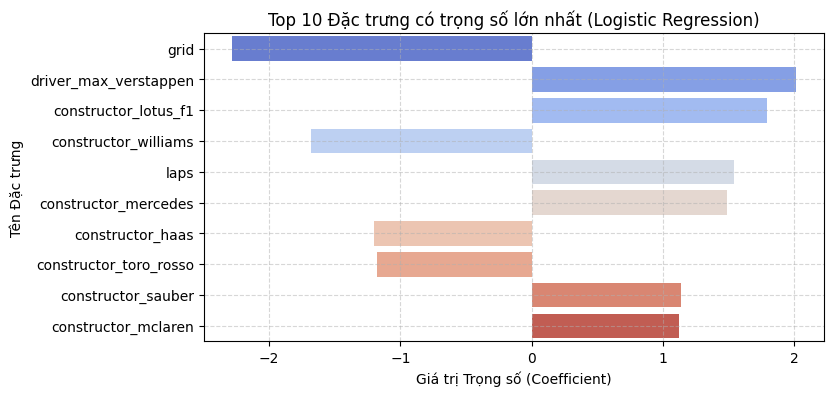

In [91]:


# 1. Phân tích lỗi (Error Analysis)
df_error = X_test.copy()
df_error['y_true'] = y_test.values
df_error['y_pred'] = y_pred
errors = df_error[df_error['y_true'] != df_error['y_pred']]

print(f'- Tổng số ca dự đoán sai: {len(errors):,} / {len(y_test):,}')

# 2. Biểu đồ trọng số đặc trưng (Coefficients Barplot)
cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
encoded_cat_features = cat_encoder.get_feature_names_out(cat_features).tolist()
all_feature_names = num_features + encoded_cat_features

df_vis = pd.DataFrame(
    {'Feature': all_feature_names, 'Coefficient': model.coef_[0]}
)
df_vis['Abs_Coef'] = df_vis['Coefficient'].abs()
df_vis = df_vis.sort_values(by='Abs_Coef', ascending=False).head(10)

plt.figure(figsize=(8, 4))
sns.barplot(x='Coefficient', y='Feature', data=df_vis, palette='coolwarm')
plt.title('Top 10 Đặc trưng có trọng số lớn nhất (Logistic Regression)')
plt.xlabel('Giá trị Trọng số (Coefficient)')
plt.ylabel('Tên Đặc trưng')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Dự đoán kết quả cho một chặng đua cụ thể**

In [92]:
# 1. Tự tạo một dòng dữ liệu giả lập cho chặng đua mới
custom_data = pd.DataFrame(
    {
        'season': [2026],
        'round': [1],
        'date': ['2026-03-15'],  # Cột phụ, sẽ bị loại bỏ
        'circuit': [
            'Bahrain Grand Prix'
        ],  # Tên trường đua (nên trùng với tên trong data mẫu của bạn)
        'driver': ['Max Verstappen'],  # Tên tay đua
        'constructor': ['Red Bull Racing'],  # Tên đội đua
        'grid': [
            15
        ],  # Vị trí xuất phát cực tốt (Pole position -> xác suất lên podium rất cao)
        'position': [1],  # Cột phụ (không dùng cho dự đoán)
        'points': [25],  # Cột phụ (không dùng cho dự đoán)
        'status': ['Finished'],  # Cột phụ (không dùng cho dự đoán)
        'laps': [70],  # Số vòng đua
        'recent_avg_grid': [15],  # Phong độ vị trí xuất phát 3 chặng gần nhất tốt
        'circuit_driver_podium_rate': [
            0.05
        ],  # Tỷ lệ lên podium lịch sử tại trường đua này cao
    }
)

# 2. Loại bỏ các cột không gian đặc trưng (giống hệt cách xử lý tập X)
X_custom = custom_data.drop(
    columns=['is_podium', 'position', 'date', 'status', 'points'],
    errors='ignore',
)

# 3. Tiền xử lý thông qua preprocessor đã học sẵn từ tập Train
X_custom_processed = preprocessor.transform(X_custom)

# 4. Dự đoán bằng mô hình Logistic Regression
custom_prob = model.predict_proba(X_custom_processed)[:, 1][0]
custom_pred = model.predict(X_custom_processed)[0]

# 5. In kết quả trực quan
print('KIỂM TRA MÔ HÌNH VỚI DỮ LIỆU BẤT KÌ')
print(
    f"Tay đua: {custom_data['driver'].values[0]} | Đội: {custom_data['constructor'].values[0]}"
)
print(f'Vị trí xuất phát (Grid): {custom_data["grid"].values[0]}')
print(f'Phong độ gần đây (Recent Grid): {custom_data["recent_avg_grid"].values[0]}')
print(
    f'Tỷ lệ Podium lịch sử tại trường đua:'
    f' {custom_data["circuit_driver_podium_rate"].values[0]}'
)
print('--------------------------------------------------')
print(f'Xác suất dự đoán lên Podium: {custom_prob * 100:.2f}%')
if custom_pred == 1:
    print(
        ' Kết luận của mô hình: DỰ ĐOÁN LÊN PODIUM (CÓ CUP) (Top 3) - Mô hình đánh giá'
        ' cơ hội rất cao!'
    )
else:
    print(
        'Kết luận của mô hình: DỰ ĐOÁN KHÔNG LÊN PODIUM (KHÔNG CÓ CUP) - Cơ hội lọt top 3'
        ' thấp.'
    )

KIỂM TRA MÔ HÌNH VỚI DỮ LIỆU BẤT KÌ
Tay đua: Max Verstappen | Đội: Red Bull Racing
Vị trí xuất phát (Grid): 15
Phong độ gần đây (Recent Grid): 15
Tỷ lệ Podium lịch sử tại trường đua: 0.05
--------------------------------------------------
Xác suất dự đoán lên Podium: 0.97%
Kết luận của mô hình: DỰ ĐOÁN KHÔNG LÊN PODIUM (KHÔNG CÓ CUP) - Cơ hội lọt top 3 thấp.
